#**Malware Analysis: Using Explainable AI for Classification and Reporting**
##**Final Year Project for BSc Cybersecurity**
##**By Hafsa Qazi**

In [1]:
# Importing libraries

import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
import tensorflow as tf
from scipy.sparse import load_npz, csr_matrix, save_npz
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    average_precision_score,
    roc_auc_score,
    roc_curve,
    f1_score
)

# Explainability libraries
!pip -q install shap lime
import lime
import lime.lime_tabular
import shap

# Make DataFrame output easier to read in the notebook.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="muted")
print("✓ Libraries loaded")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 2.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
✓ Libraries loaded


In [2]:
# Connecting to Google Drive to access MalwareDataset.csv
from google.colab import drive
drive.mount('/content/drive')

#Pointing to the folder containg the dataset
data_dir = "/content/drive/MyDrive/Datasets"
csv_files = [f for f in os.listdir(data_dir) if f.lower().endswith(".csv")]
print("CSV files found:", csv_files)
csv_path = os.path.join(data_dir, csv_files[0])

# Load dataset into a DataFrame and inspect
df = pd.read_csv(csv_path)
print("Loaded:", csv_path)
print("Shape:", df.shape)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CSV files found: ['MalwareDataset.csv']
Loaded: /content/drive/MyDrive/Datasets/MalwareDataset.csv
Shape: (100000, 35)


,hash,millisecond,classification,state,usage_counter,prio,static_prio,normal_prio,policy,vm_pgoff,vm_truncate_count,task_size,cached_hole_size,free_area_cache,mm_users,map_count,hiwater_rss,total_vm,shared_vm,exec_vm,reserved_vm,nr_ptes,end_data,last_interval,nvcsw,nivcsw,min_flt,maj_flt,fs_excl_counter,lock,utime,stime,gtime,cgtime,signal_nvcsw
0,42fb5e2ec009a05ff5143227297074f1e9c6c3ebb9c914...,0,malware,0,0,3069378560,14274,0,0,0,13173,0,0,24,724,6850,0,150,120,124,210,0,120,3473,341974,0,0,120,0,3204448256,380690,4,0,0,0
1,42fb5e2ec009a05ff5143227297074f1e9c6c3ebb9c914...,1,malware,0,0,3069378560,14274,0,0,0,13173,0,0,24,724,6850,0,150,120,124,210,0,120,3473,341974,0,0,120,0,3204448256,380690,4,0,0,0
2,42fb5e2ec009a05ff5143227297074f1e9c6c3ebb9c914...,2,malware,0,0,3069378560,14274,0,0,0,13173,0,0,24,724,6850,0,150,120,124,210,0,120,3473,341974,0,0,120,0,3204448256,380690,4,0,0,0
3,42fb5e2ec009a05ff5143227297074f1e9c6c3ebb9c914...,3,malware,0,0,3069378560,14274,0,0,0,13173,0,0,24,724,6850,0,150,120,124,210,0,120,3473,341974,0,0,120,0,3204448256,380690,4,0,0,0
4,42fb5e2ec009a05ff5143227297074f1e9c6c3ebb9c914...,4,malware,0,0,3069378560,14274,0,0,0,13173,0,0,24,724,6850,0,150,120,124,210,0,120,3473,341974,0,0,120,0,3204448256,380690,4,0,0,0



Dataset shape: (100000, 35)
Missing values total: 0

Classification column values:
classification
malware    50000
benign     50000
Name: count, dtype: int64

Number of unique classes: 2

Imbalance ratio (majority:minority): 1.0:1
  → Majority class: malware (50000 samples)
  → Minority class: malware (50000 samples)



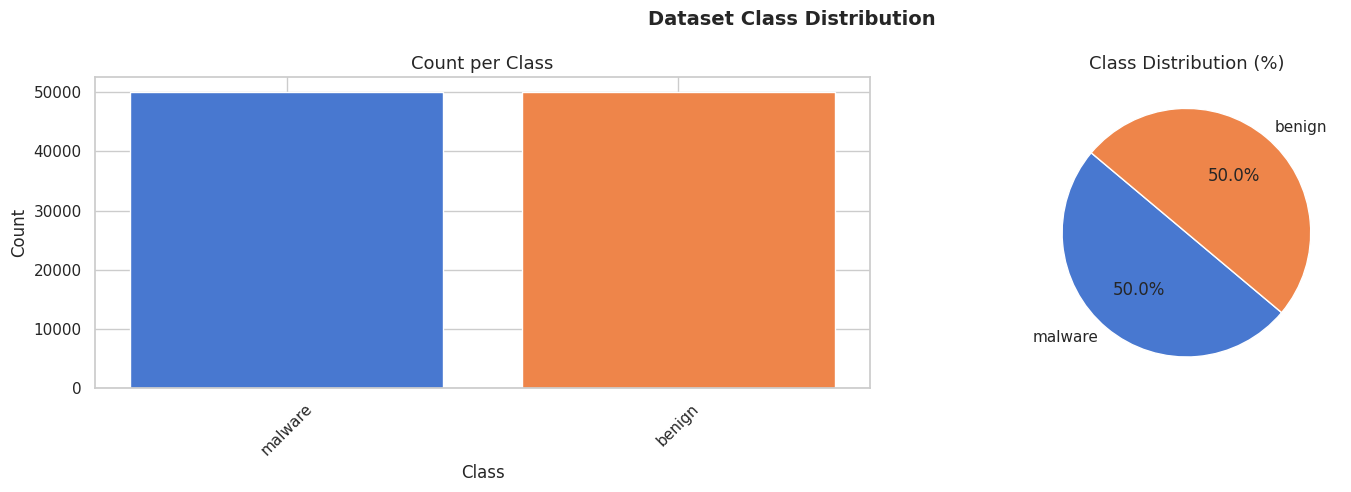

In [3]:
# Data Analysis before splitting data

# Basic info
print(f"\nDataset shape: {df.shape}")
print(f"Missing values total: {df.isnull().sum().sum()}")
print(f"\nClassification column values:\n{df['classification'].value_counts()}")

# Identify attack types
label_counts = df['classification'].value_counts()
n_classes = len(label_counts)
print(f"\nNumber of unique classes: {n_classes}")

# Imbalance ratio
majority = label_counts.max()
minority = label_counts.min()
print(f"\nImbalance ratio (majority:minority): {majority/minority:.1f}:1")
print(f"  → Majority class: {label_counts.idxmax()} ({majority} samples)")
print(f"  → Minority class: {label_counts.idxmin()} ({minority} samples)\n")

# Class imbalance visualisation
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Bar chart
axes[0].bar(label_counts.index, label_counts.values, color=sns.color_palette("muted", n_classes))
axes[0].set_title("Count per Class", fontsize=13)
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis='x', rotation=45)

# Pie chart
axes[1].pie(
    label_counts.values,
    labels=label_counts.index,
    autopct="%1.1f%%",
    colors=sns.color_palette("muted", n_classes),
    startangle=140
)
axes[1].set_title("Class Distribution (%)", fontsize=13)

plt.suptitle("Dataset Class Distribution", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(data_dir, "class_distribution.png"), dpi=150, bbox_inches="tight")
plt.show()

In [4]:
# Preprocessing and Splitting Data (80/20)
# Drop columns or columns not suitable for features
columns_to_drop = ['Unnamed: 0', 'Flow ID', 'Timestamp','hash', 'classification', 'state', 'prio', 'utime', 'nvcsw', 'usage_counter', 'millisecond']
df_processed = df.copy()

# Attempt to convert relevant columns to numerics
for col in df_processed.columns:
    if col not in columns_to_drop:
        # Attempt to convert to numeric, setting non-convertible values to NaN
        df_processed[col] = pd.to_numeric(df_processed[col], errors='coerce')

# Drop rows where 'Label' is missing if any
df_processed.dropna(subset=['classification'], inplace=True)
df_processed.fillna(0, inplace=True)

# Encode multi-class labels to integers
le = LabelEncoder()
y_encoded = le.fit_transform(df_processed['classification'])
class_names = le.classes_

# Binary label: 0 = BENIGN, MALWARE = 1
# Corrected: changed 'Benign' to 'benign' to match actual data
y_binary = (df_processed['classification'] != 'benign').astype(int).values
y_multi = y_encoded

# Separate features (X) and target (y)
X = df_processed.drop(columns=columns_to_drop, errors='ignore')
y = df_processed['classification']

# Convert features to a sparse matrix format
X_sparse = csr_matrix(X.values)

# Split the data into training and testing sets
# Using a common test size of 0.2 (20%) and a random state for reproducibility
X_train, X_test, y_train, y_test = train_test_split(X_sparse, y, test_size=0.2, random_state=42)

print("Data splitting complete.")
print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Stratified split preserves class proportions
X_train, X_test, y_train_b, y_test_b, y_train_m, y_test_m = train_test_split(
    X_sparse, y_binary, y_multi,
    test_size=0.2, random_state=42, stratify=y_binary
)

print(f"\nFeatures: {X_sparse.shape[1]}")
print(f"Train samples: {X_train.shape[0]:,}  |  Test samples: {X_test.shape[0]:,}")
print(f"\nBinary test distribution:")
print(pd.Series(y_test_b).map({0: 'BENIGN', 1: 'MALWARE'}).value_counts())

# Saving preprocessed data (.npz; sparce matrix format)
save_npz(os.path.join(data_dir, "training_data.npz"), X_train)
save_npz(os.path.join(data_dir, "test_data.npz"), X_test)
np.save(os.path.join(data_dir, "training_labels_binary.npy"), y_train_b) # Binary labels saved and used
np.save(os.path.join(data_dir, "test_labels_binary.npy"), y_test_b)      # Binary labels saved and used
np.save(os.path.join(data_dir, "training_labels_multi.npy"), y_train_m)  # Multiclass labels saved for future use
np.save(os.path.join(data_dir, "test_labels_multi.npy"), y_test_m)       # Multiclass labels saved for future u
np.save(os.path.join(data_dir, "class_names.npy"), class_names)
print("\nFiles saved to:", data_dir)
print("\n✓ Data saved.")

Data splitting complete.

X_train shape: (80000, 27)
X_test shape: (20000, 27)
y_train shape: (80000,)
y_test shape: (20000,)

Features: 27
Train samples: 80,000  |  Test samples: 20,000

Binary test distribution:
MALWARE    10000
BENIGN     10000
Name: count, dtype: int64

Files saved to: /content/drive/MyDrive/Datasets

✓ Data saved.


In [5]:
# Loading the pre-processed files
X_train = load_npz(os.path.join(data_dir, "training_data.npz"))
X_test  = load_npz(os.path.join(data_dir, "test_data.npz"))

y_train_b = np.load(os.path.join(data_dir, "training_labels_binary.npy"))
y_test_b  = np.load(os.path.join(data_dir, "test_labels_binary.npy"))
y_train_m = np.load(os.path.join(data_dir, "training_labels_multi.npy"))
y_test_m  = np.load(os.path.join(data_dir, "test_labels_multi.npy"))
class_names = np.load(os.path.join(data_dir, "class_names.npy"), allow_pickle=True)

# Dense arrays needed by LIME / SHAP / Neural Network
X_train_dense = X_train.toarray().astype(np.float32)
X_test_dense  = X_test.toarray().astype(np.float32)

# Feature names (needed by LIME & SHAP)
feature_names = X.columns.tolist()   # X was defined in the pre-processing cell

print(f"✓ Data loaded  |  train={X_train.shape}  test={X_test.shape}")
print(f"  Binary classes : {np.unique(y_test_b)}")
print(f"  Multi  classes : {class_names}")

# Feature scaling
scaler = StandardScaler() # Each feature should have a mean of 0 and standard deviation of 1
X_train_scaled = scaler.fit_transform(X_train_dense) # Learns the mean and standard deviation from the training data only
X_test_scaled  = scaler.transform(X_test_dense) # Applying transformation learned from training data to the test data
joblib.dump(scaler, os.path.join(data_dir, "scaler.pkl"))
print("✓ Scaler fitted and saved")

✓ Data loaded  |  train=(80000, 27)  test=(20000, 27)
  Binary classes : [0 1]
  Multi  classes : ['benign' 'malware']
✓ Scaler fitted and saved


In [6]:
# Defining the security relevant metrics

def security_metrics(y_true, y_pred, label="Model"):

    cm = confusion_matrix(y_true, y_pred)

    # Expect binary: 0=benign, 1=malware
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
    else:
        raise ValueError("Expected 2x2 confusion matrix for binary labels.")

    fpr  = fp / (fp + tn) if (fp + tn) > 0 else 0 # Benign samples flagged as malware (recall)
    fnr  = fn / (fn + tp) if (fn + tp) > 0 else 0 # Malware samples flagged as benign (1-recall)
    dr   = tp / (tp + fn) if (tp + fn) > 0 else 0 # Detection Rate
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0 # Precison
    acc  = accuracy_score(y_true, y_pred)
    bal  = balanced_accuracy_score(y_true, y_pred)

    return {
        "Model": label,
        "Accuracy": round(acc, 4),
        "Balanced Accuracy": round(bal, 4),
        "Detection Rate (DR)": round(dr, 4),
        "False Positive Rate (FPR)": round(fpr, 4),
        "False Negative Rate (FNR)": round(fnr, 4),
        "Precision": round(prec, 4),
        "F1 (Malware)": round(f1_score(y_true, y_pred, pos_label=1), 4),
        "TP": tp, "TN": tn, "FP": fp, "FN": fn
    }

print("✓ security_metrics() helper defined")

✓ security_metrics() helper defined


In [7]:
# Classical ML models (binary)
models_binary = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=15, min_samples_leaf=10, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=20, min_samples_leaf=5,
        class_weight="balanced", n_jobs=-1, random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.1, max_depth=5,
        subsample=0.8, random_state=42
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced",
        solver="lbfgs", C=1.0, random_state=42
    ),
    # SVM wrapped for probability support (needed for ROC / SHAP)
    "SVM": CalibratedClassifierCV(
        SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=42),
        cv=3
    ),
}

# Neural Network (Keras, binary)
def build_nn(input_dim: int) -> keras.Model:
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(256, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid"),   # binary output
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

print("✓ Model definitions ready")

✓ Model definitions ready


In [8]:
# Model Training & Evaluation Loop
results = []          # To store security metrics
trained_models = {}   # To store each fitted model
roc_data = {}         # To stor ROC curve data
pr_data  = {}         # To store precision-recall data


# Classical Machine Learing Algorithms
for name, clf in models_binary.items():
    save_path = os.path.join(data_dir, f"model_{name.replace(' ', '_')}.pkl")

    if os.path.exists(save_path):
        # Load
        print(f"  →  Loading  {name} from cache …", end=" ")
        clf = joblib.load(save_path)
        print("done")
    else:
        # Train
        print(f"\n→  Training {name} …", end=" ")
        if name in ("Logistic Regression", "SVM"):
            clf.fit(X_train_scaled, y_train_b)
        else:
            clf.fit(X_train, y_train_b)
        joblib.dump(clf, save_path)
        print(f"done  →  saved to {save_path}")

    trained_models[name] = clf

    # Predict
    if name in ("Logistic Regression", "SVM"):
      y_pred = clf.predict(X_test_scaled)
      proba  = clf.predict_proba(X_test_scaled)
    else:
      y_pred = clf.predict(X_test)
      proba  = clf.predict_proba(X_test)

    # Safely extract the positive-class (malware) probability column
    if proba.ndim == 1 or proba.shape[1] == 1:
        y_prob = proba.ravel()
    elif hasattr(clf, "classes_") and 1 in clf.classes_:
        pos_col = list(clf.classes_).index(1)
        y_prob  = proba[:, pos_col]
    else:
        y_prob = proba[:, 1]

    # Security metrics
    m = security_metrics(y_test_b, y_pred, label=name)
    m["ROC-AUC"] = round(roc_auc_score(y_test_b, y_prob), 4)
    results.append(m)

    # ROC / PR curve data
    fpr_arr, tpr_arr, _ = roc_curve(y_test_b, y_prob)
    roc_data[name] = (fpr_arr, tpr_arr, m["ROC-AUC"])

    prec_arr, rec_arr, _ = precision_recall_curve(y_test_b, y_prob)
    ap_val = average_precision_score(y_test_b, y_prob)
    pr_data[name] = (prec_arr, rec_arr, round(ap_val, 4))


→  Training Decision Tree … done  →  saved to /content/drive/MyDrive/Datasets/model_Decision_Tree.pkl

→  Training Random Forest … done  →  saved to /content/drive/MyDrive/Datasets/model_Random_Forest.pkl

→  Training Gradient Boosting … done  →  saved to /content/drive/MyDrive/Datasets/model_Gradient_Boosting.pkl

→  Training Logistic Regression … done  →  saved to /content/drive/MyDrive/Datasets/model_Logistic_Regression.pkl

→  Training SVM … done  →  saved to /content/drive/MyDrive/Datasets/model_SVM.pkl


In [9]:
# Training Neural Network
nn_save_path     = os.path.join(data_dir, "model_NeuralNetwork.h5")
nn_history_path  = os.path.join(data_dir, "nn_history.npy")

if os.path.exists(nn_save_path):
    # Load
    print(f"\n  → Loading  Neural Network from cache …", end=" ")
    nn_model = keras.models.load_model(nn_save_path)
    # Restore history for the loss-curve plot if it was saved previously
    history_data = (np.load(nn_history_path, allow_pickle=True).item()
                    if os.path.exists(nn_history_path) else None)
    print("done")
else:
    # Train
    print("\n→  Training Neural Network …")
    nn_model = build_nn(X_train_scaled.shape[1])

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    )
    lr_reduce = keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=0
    )

    history_obj = nn_model.fit(
        X_train_scaled, y_train_b,
        validation_split=0.1,
        epochs=50,
        batch_size=512,
        callbacks=[early_stop, lr_reduce],
        verbose=1
    )
    history_data = history_obj.history

    nn_model.save(nn_save_path)
    np.save(nn_history_path, history_data)          # persist loss curves
    print(f"✓ Neural Network trained  →  saved to {nn_save_path}")

y_prob_nn = nn_model.predict(X_test_scaled).flatten()
y_pred_nn = (y_prob_nn >= 0.5).astype(int)

m_nn = security_metrics(y_test_b, y_pred_nn, label="Neural Network")
m_nn["ROC-AUC"] = round(roc_auc_score(y_test_b, y_prob_nn), 4)
results.append(m_nn)

fpr_nn, tpr_nn, _ = roc_curve(y_test_b, y_prob_nn)
roc_data["Neural Network"] = (fpr_nn, tpr_nn, m_nn["ROC-AUC"])

prec_nn, rec_nn, _ = precision_recall_curve(y_test_b, y_prob_nn)
ap_nn = average_precision_score(y_test_b, y_prob_nn)
pr_data["Neural Network"] = (prec_nn, rec_nn, round(ap_nn, 4))

trained_models["Neural Network"] = nn_model


→  Training Neural Network …
Epoch 1/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9334 - loss: 0.1699 - val_accuracy: 0.9925 - val_loss: 0.1278 - learning_rate: 0.0010
Epoch 2/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9875 - loss: 0.0353 - val_accuracy: 0.9970 - val_loss: 0.0197 - learning_rate: 0.0010
Epoch 3/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9933 - loss: 0.0194 - val_accuracy: 0.9981 - val_loss: 0.0074 - learning_rate: 0.0010
Epoch 4/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.9953 - loss: 0.0130 - val_accuracy: 0.9933 - val_loss: 0.0123 - learning_rate: 0.0010
Epoch 5/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9970 - loss: 0.0087 - val_accuracy: 0.9990 - val_loss: 0.0027 - learning_rate: 0.0010
Epoch 6/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9981 - loss: 0.0059 - val_accuracy: 0.9994 - val_loss: 0.0022 - learning_rate: 0.0010
Epoch 7/50
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step

✓ Neural Network trained  →  saved to /content/drive/MyDrive/Datasets/model_NeuralNetwork.h5
625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


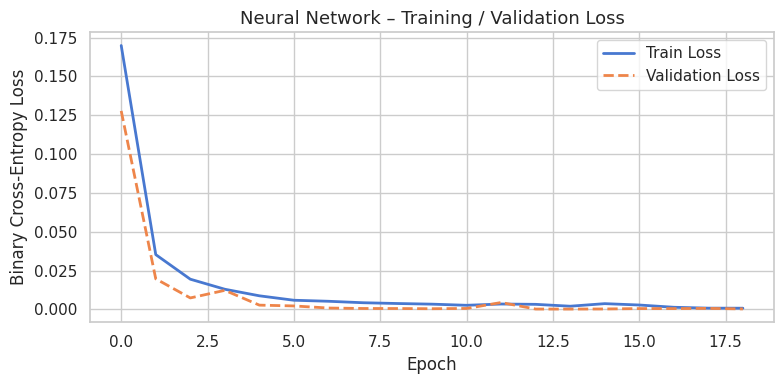

In [10]:
# Training-loss plot for NN
if history_data is not None:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(history_data["loss"],     label="Train Loss",      linewidth=2)
    ax.plot(history_data["val_loss"], label="Validation Loss", linewidth=2, linestyle="--")
    ax.set_title("Neural Network – Training / Validation Loss", fontsize=13)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Binary Cross-Entropy Loss")
    ax.legend(); plt.tight_layout()
    plt.savefig(os.path.join(data_dir, "nn_loss_curve.png"), dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("  (Loss-curve plot skipped – history not available for loaded model)")

In [11]:
# Results table
results_df = pd.DataFrame(results).set_index("Model")
# Display rounded table (drop raw TP/TN/FP/FN for cleanliness here)
display_cols = ["Accuracy", "Balanced Accuracy", "Detection Rate (DR)",
  "False Positive Rate (FPR)", "False Negative Rate (FNR)",
  "Precision", "F1 (Malware)", "ROC-AUC"]

print("\nSecurity Metrics – All Models")
print(results_df[display_cols].to_string())
results_df.to_csv(os.path.join(data_dir, "model_results.csv"))
print("\n✓ Results table saved to model_results.csv")


Security Metrics – All Models
                     Accuracy  Balanced Accuracy  Detection Rate (DR)  False Positive Rate (FPR)  False Negative Rate (FNR)  Precision  F1 (Malware)  ROC-AUC
Model                                                                                                                                                        
Decision Tree          0.9999             0.9999               0.9998                     0.0000                     0.0002     1.0000        0.9999   1.0000
Random Forest          1.0000             1.0000               1.0000                     0.0000                     0.0000     1.0000        1.0000   1.0000
Gradient Boosting      1.0000             1.0000               1.0000                     0.0000                     0.0000     1.0000        1.0000   1.0000
Logistic Regression    0.8697             0.8696               0.8895                     0.1502                     0.1105     0.8555        0.8722   0.9554
SVM                  

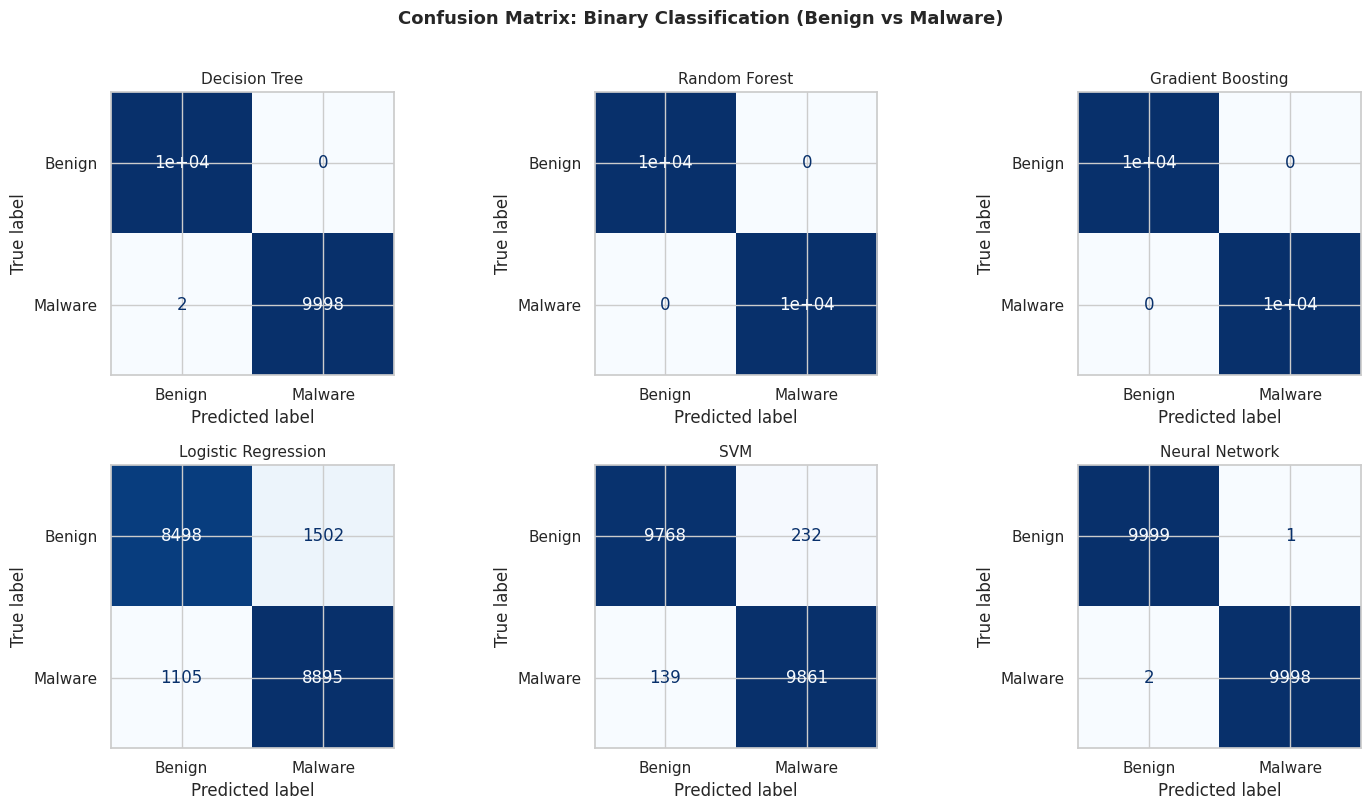

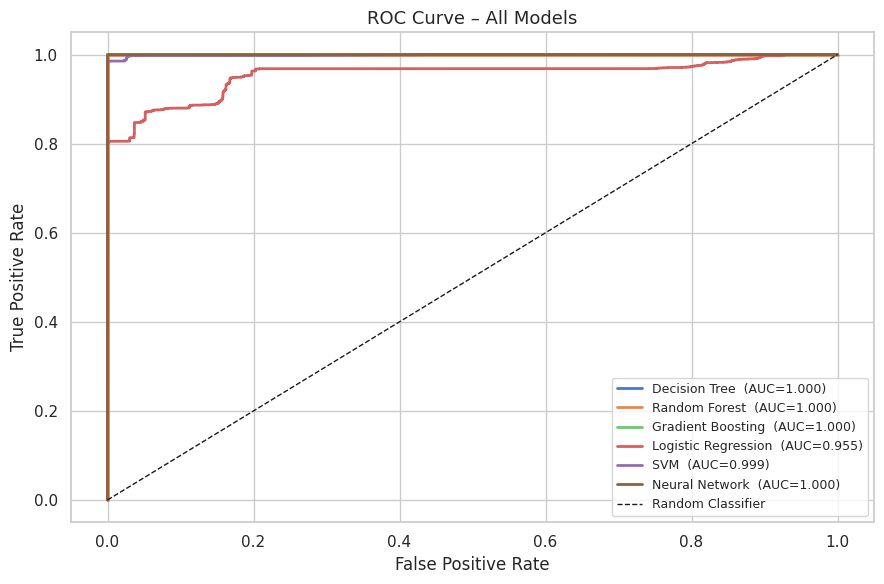

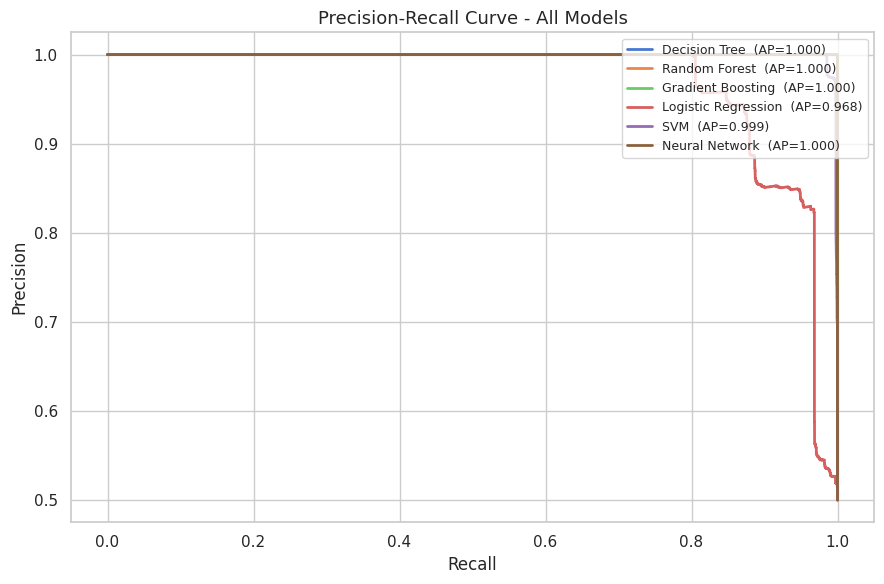

In [12]:
# Visualising Results
n_models   = len(trained_models)
n_cols     = 3
n_rows     = (n_models + n_cols - 1) // n_cols
fig, axes  = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes       = axes.flatten()

for idx, (name, clf) in enumerate(trained_models.items()):
    if name == "Neural Network":
        y_pred_i = y_pred_nn
    elif name in ("Logistic Regression", "SVM"):
        y_pred_i = clf.predict(X_test_scaled)
    else:
        y_pred_i = clf.predict(X_test)

    cm = confusion_matrix(y_test_b, y_pred_i)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malware"])
    disp.plot(ax=axes[idx], colorbar=False, cmap="Blues")
    axes[idx].set_title(name, fontsize=11)

# Hide unused subplots
for j in range(idx + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Confusion Matrix: Binary Classification (Benign vs Malware)",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(data_dir, "confusion_matrices.png"), dpi=150, bbox_inches="tight")
plt.show()


# ROC Curve
fig, ax = plt.subplots(figsize=(9, 6))
colors  = sns.color_palette("muted", len(roc_data))

for (name, (fpr_arr, tpr_arr, auc_val)), color in zip(roc_data.items(), colors):
    ax.plot(fpr_arr, tpr_arr, label=f"{name}  (AUC={auc_val:.3f})",
            linewidth=2, color=color)

ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random Classifier")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve – All Models", fontsize=13)
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(data_dir, "roc_curves.png"), dpi=150, bbox_inches="tight")
plt.show()


# Precision-Recall Curves
fig, ax = plt.subplots(figsize=(9, 6))

for (name, (prec_arr, rec_arr, ap_val)), color in zip(pr_data.items(), colors):
    ax.plot(rec_arr, prec_arr, label=f"{name}  (AP={ap_val:.3f})",
            linewidth=2, color=color)

ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve - All Models", fontsize=13)
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(data_dir, "pr_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

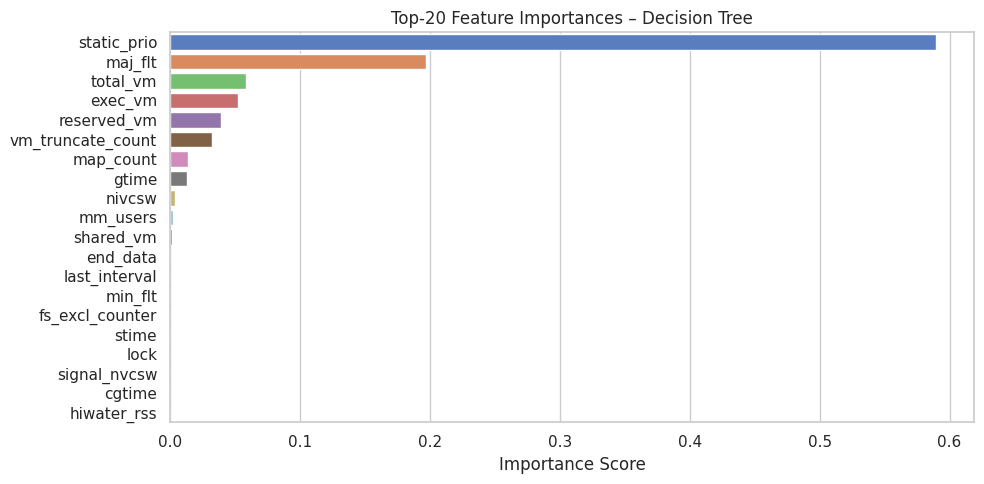

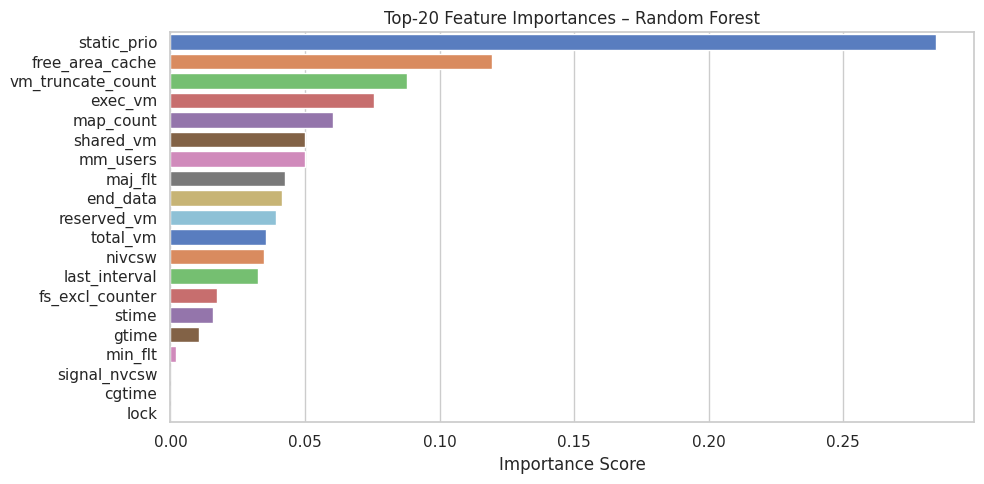

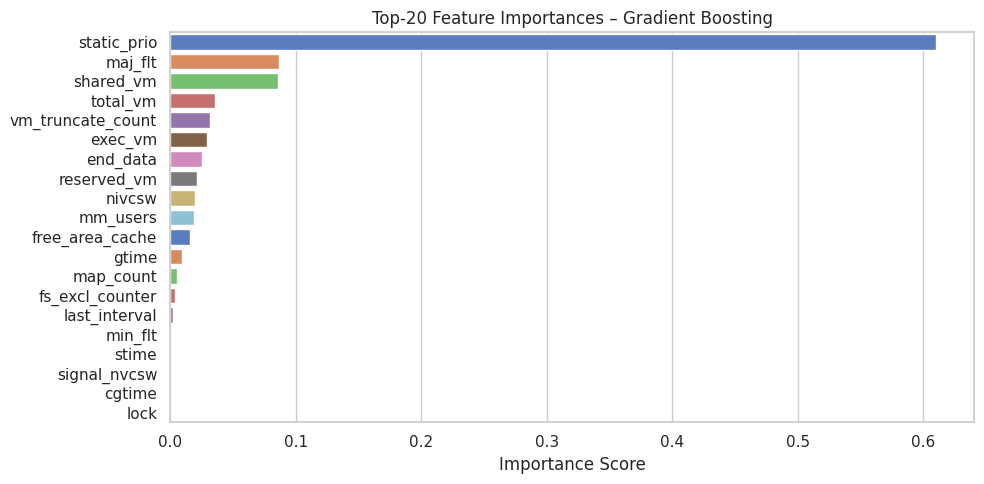

In [13]:
# Feature Importance
def plot_feature_importance(clf, feature_names, model_name, top_n=20, save_dir=None):
    if not hasattr(clf, "feature_importances_"):
        print(f"  {model_name} has no feature_importances_ – skipped")
        return
    importances = clf.feature_importances_
    idx  = np.argsort(importances)[::-1][:top_n]
    vals = importances[idx]
    names = [feature_names[i] for i in idx]

    fig, ax = plt.subplots(figsize=(10, 5))
    sns.barplot(x=vals, y=names, palette="muted", ax=ax)
    ax.set_title(f"Top-{top_n} Feature Importances – {model_name}", fontsize=12)
    ax.set_xlabel("Importance Score")
    plt.tight_layout()
    if save_dir:
        plt.savefig(
            os.path.join(save_dir, f"feat_imp_{model_name.replace(' ', '_')}.png"),
            dpi=150, bbox_inches="tight"
        )
    plt.show()


for name in ("Decision Tree", "Random Forest", "Gradient Boosting"):
    plot_feature_importance(trained_models[name], feature_names, name,
                            top_n=20, save_dir=data_dir)

In [14]:
# Best Model Selection
best_row   = results_df.sort_values(
    ["False Negative Rate (FNR)", "ROC-AUC"], ascending=[True, False]
).iloc[0]
best_name  = best_row.name
best_model = trained_models[best_name]

print(f"\nBest model selected: {best_name}")
print(best_row[display_cols])


Best model selected: Random Forest
Accuracy                     1.0
Balanced Accuracy            1.0
Detection Rate (DR)          1.0
False Positive Rate (FPR)    0.0
False Negative Rate (FNR)    0.0
Precision                    1.0
F1 (Malware)                 1.0
ROC-AUC                      1.0
Name: Random Forest, dtype: float64


✓ LIME explainer initialised


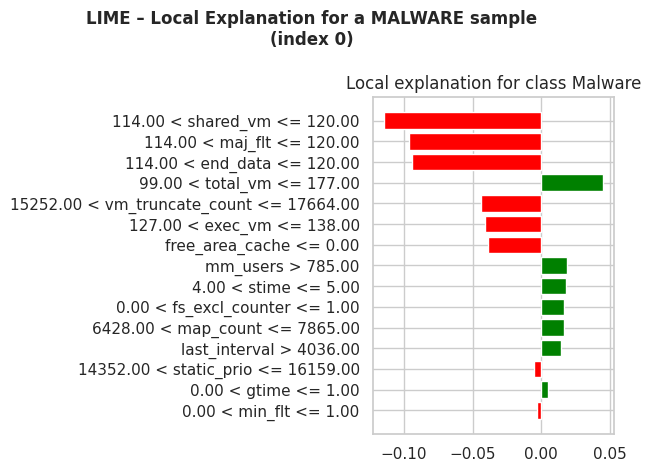


Top LIME features (malware prediction):
  114.00 < shared_vm <= 120.00                        weight=-0.1145  ↓ pushes toward Benign
  114.00 < maj_flt <= 120.00                          weight=-0.0960  ↓ pushes toward Benign
  114.00 < end_data <= 120.00                         weight=-0.0941  ↓ pushes toward Benign
  99.00 < total_vm <= 177.00                          weight=+0.0451  ↑ pushes toward Malware
  15252.00 < vm_truncate_count <= 17664.00            weight=-0.0435  ↓ pushes toward Benign
  127.00 < exec_vm <= 138.00                          weight=-0.0408  ↓ pushes toward Benign
  free_area_cache <= 0.00                             weight=-0.0385  ↓ pushes toward Benign
  mm_users > 785.00                                   weight=+0.0190  ↑ pushes toward Malware
  4.00 < stime <= 5.00                                weight=+0.0181  ↑ pushes toward Malware
  0.00 < fs_excl_counter <= 1.00                      weight=+0.0169  ↑ pushes toward Malware


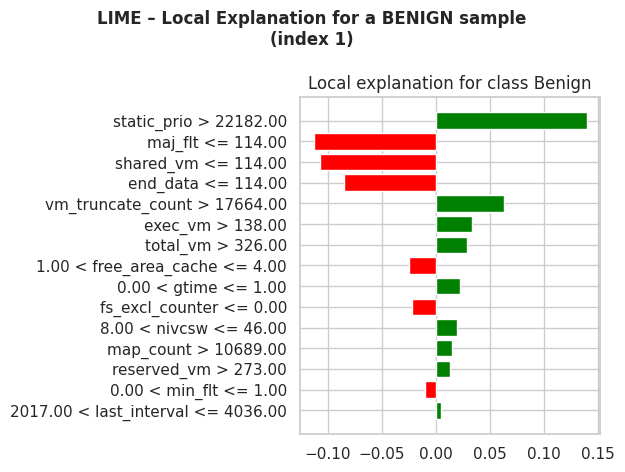


Top LIME features (benign prediction):
  static_prio > 22182.00                              weight=+0.1392  ↑ pushes toward Benign
  maj_flt <= 114.00                                   weight=-0.1130  ↓ pushes toward Malware
  shared_vm <= 114.00                                 weight=-0.1073  ↓ pushes toward Malware
  end_data <= 114.00                                  weight=-0.0847  ↓ pushes toward Malware
  vm_truncate_count > 17664.00                        weight=+0.0626  ↑ pushes toward Benign
  exec_vm > 138.00                                    weight=+0.0336  ↑ pushes toward Benign
  total_vm > 326.00                                   weight=+0.0288  ↑ pushes toward Benign
  1.00 < free_area_cache <= 4.00                      weight=-0.0247  ↓ pushes toward Malware
  0.00 < gtime <= 1.00                                weight=+0.0220  ↑ pushes toward Benign
  fs_excl_counter <= 0.00                             weight=-0.0219  ↓ pushes toward Malware

Misclassified samples in

In [15]:
# LIME Explainability
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data  = X_train_dense, # LIME works on dense arrays
    feature_names  = feature_names,
    class_names    = ["Benign", "Malware"],
    mode           = "classification",
    discretize_continuous = True,
    random_state   = 42
)
print("✓ LIME explainer initialised")

def lime_predict_fn(X_array):
    # Wrapper
    if best_name == "Neural Network":
        probs = best_model.predict(scaler.transform(X_array)).flatten() # Scale input
        return np.column_stack([1 - probs, probs]) # Output is scaled into two-class probabilities
    elif best_name in ("Logistic Regression", "SVM"):
        return best_model.predict_proba(scaler.transform(X_array)) # Scale input
    else:
        return best_model.predict_proba(X_array) # Scaling not needed

# Explaining a malware sample
malware_idx = np.where(y_test_b == 1)[0][0]   # first malware in test set

lime_exp_malware = lime_explainer.explain_instance(
    data_row       = X_test_dense[malware_idx],
    predict_fn     = lime_predict_fn,
    num_features   = 15,   # 15 most influential features
    num_samples    = 1000, # number of pretubed samples
    labels         = (1,)  # Focusing on class 1 (malware)
)

fig = lime_exp_malware.as_pyplot_figure(label=1)
fig.suptitle(f"LIME – Local Explanation for a MALWARE sample\n(index {malware_idx})",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(data_dir, "lime_malware_sample.png"), dpi=150, bbox_inches="tight")
plt.show()

print("\nTop LIME features (malware prediction):")
for feat, weight in lime_exp_malware.as_list(label=1)[:10]:
    direction = "↑ pushes toward Malware" if weight > 0 else "↓ pushes toward Benign"
    print(f"  {feat:50s}  weight={weight:+.4f}  {direction}")


# Explaining a benign sample
benign_idx = np.where(y_test_b == 0)[0][0]

lime_exp_benign = lime_explainer.explain_instance(
    data_row   = X_test_dense[benign_idx],
    predict_fn = lime_predict_fn,
    num_features = 15,    # 15 most influential features
    num_samples  = 1000,  # number of pretubed samples
    labels       = (0,)   # Focusing on class 0 (benign)
)

fig = lime_exp_benign.as_pyplot_figure(label=0)
fig.suptitle(f"LIME – Local Explanation for a BENIGN sample\n(index {benign_idx})",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(data_dir, "lime_benign_sample.png"), dpi=150, bbox_inches="tight")
plt.show()

print("\nTop LIME features (benign prediction):")
for feat, weight in lime_exp_benign.as_list(label=0)[:10]:
    direction = "↑ pushes toward Benign" if weight > 0 else "↓ pushes toward Malware"
    print(f"  {feat:50s}  weight={weight:+.4f}  {direction}")


# LIME stability: explain N misclassified samples
if best_name == "Neural Network":
    y_pred_best = (best_model.predict(X_test_scaled).flatten() >= 0.5).astype(int)
elif best_name in ("Logistic Regression", "SVM"):
    y_pred_best = best_model.predict(X_test_scaled)
else:
    y_pred_best = best_model.predict(X_test)

misclassified = np.where(y_pred_best != y_test_b)[0]
print(f"\nMisclassified samples in test set: {len(misclassified)}")

if len(misclassified) > 0:
    mc_idx = misclassified[0]
    lime_exp_mc = lime_explainer.explain_instance(
        data_row   = X_test_dense[mc_idx],
        predict_fn = lime_predict_fn,
        num_features = 15,
        num_samples  = 1000,
        labels       = (1,)
    )
    true_label = "Malware" if y_test_b[mc_idx] == 1 else "Benign"
    pred_label = "Malware" if y_pred_best[mc_idx] == 1 else "Benign"

    fig = lime_exp_mc.as_pyplot_figure(label=1)
    fig.suptitle(
        f"LIME – Misclassified Sample (True={true_label}, Predicted={pred_label})",
        fontsize=12, fontweight="bold"
    )
    plt.tight_layout()
    plt.savefig(os.path.join(data_dir, "lime_misclassified.png"), dpi=150, bbox_inches="tight")
    plt.show()

print("✓ LIME explanations complete")


→  Computing SHAP values for: Random Forest  (subset of 500 test samples) …
   SHAP values shape: (500, 27, 2)  |  base value: 0.5000
   shap_vals shape after extraction: (500, 27)
   Masked 11 columns from plots
   Remaining features for plots: 16


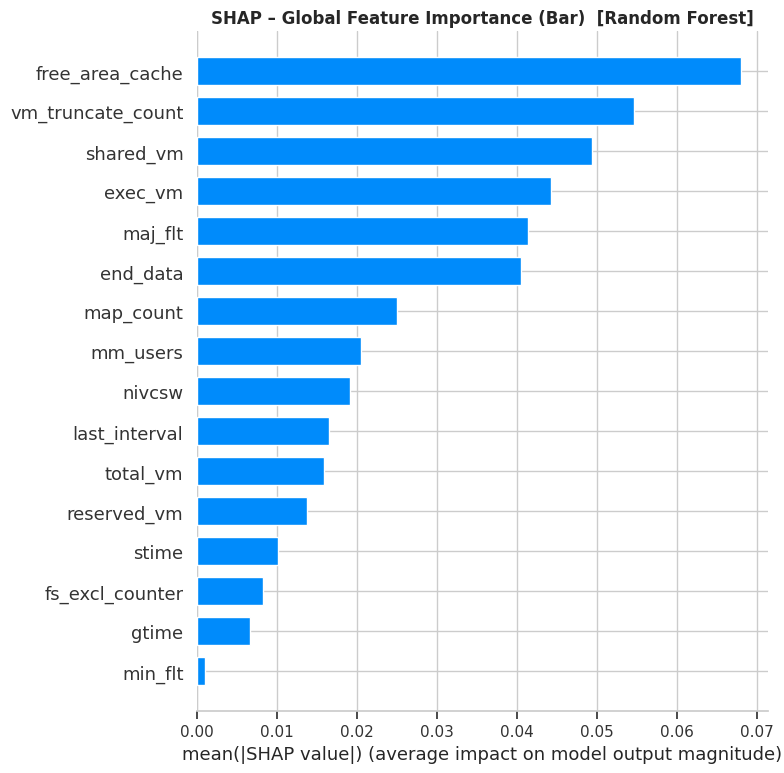

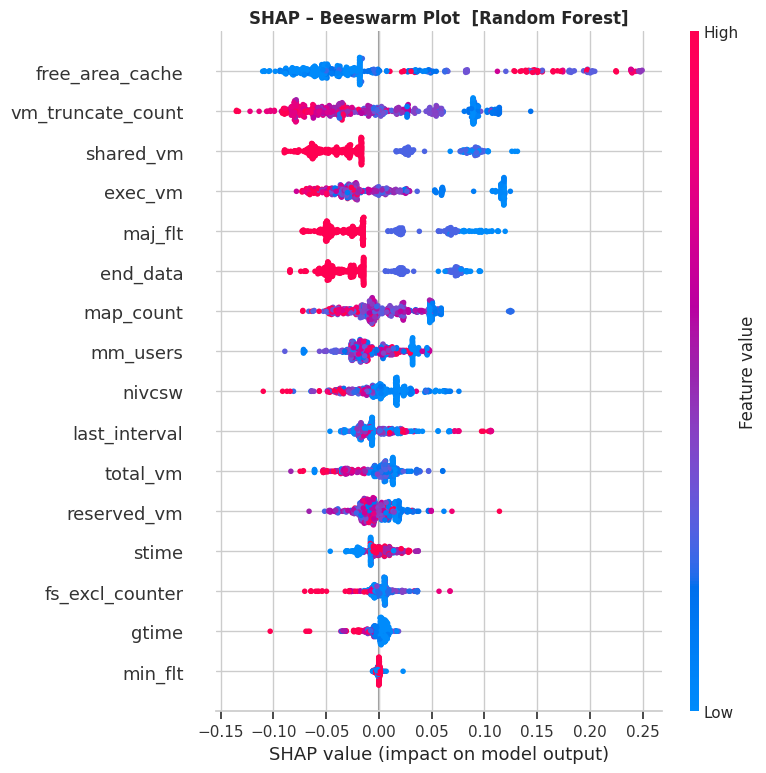

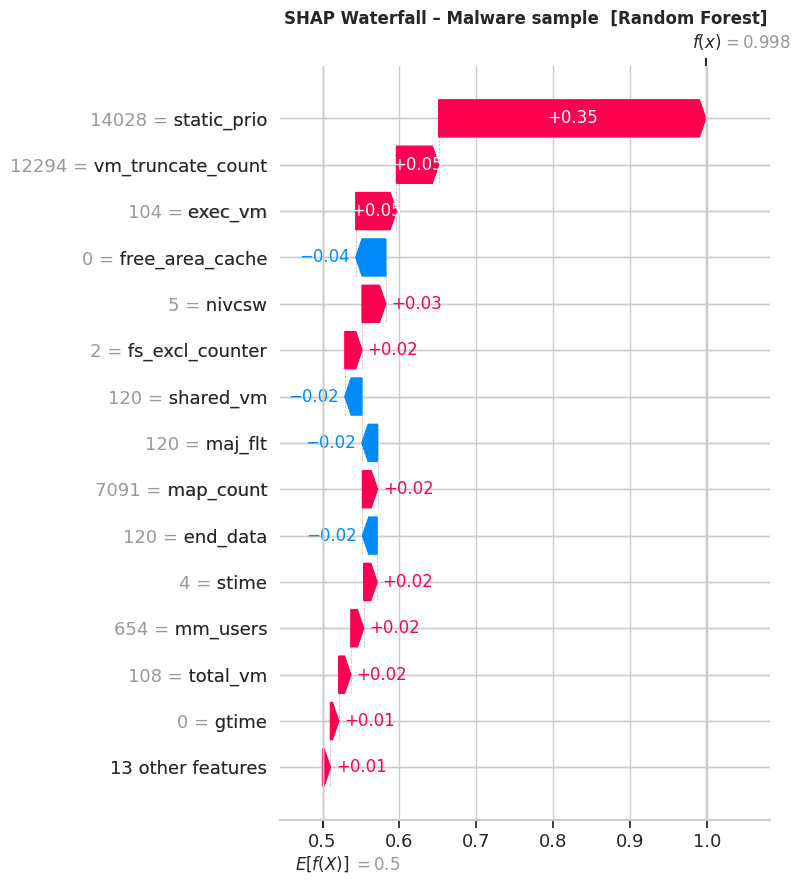

<Figure size 800x500 with 0 Axes>

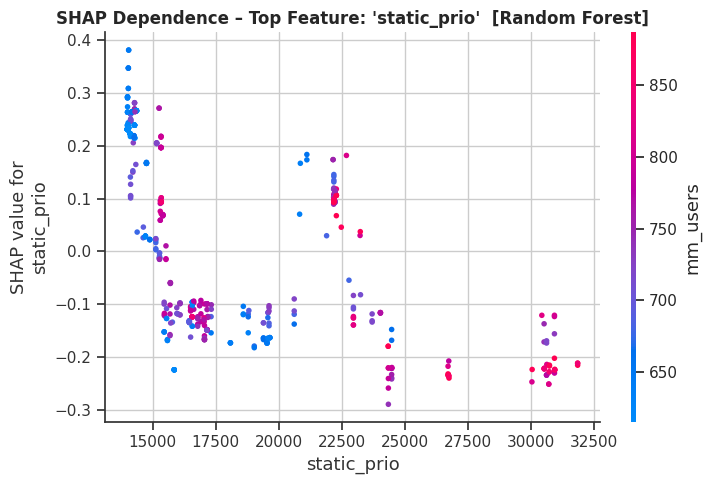

✓ SHAP explanations complete

Top 10 features by mean absolute SHAP value:
              feature  mean_abs_shap
0         static_prio       0.160640
7     free_area_cache       0.067988
4   vm_truncate_count       0.054654
12          shared_vm       0.049396
13            exec_vm       0.044254
20            maj_flt       0.041411
16           end_data       0.040489
9           map_count       0.024982
8            mm_users       0.020557
18             nivcsw       0.019185


In [16]:
# SHAP Expalinability
shap.initjs()  # enables JS plots in Colab

# Background
BACKGROUND_SIZE = 200
bg_idx       = np.random.RandomState(42).choice(X_train_dense.shape[0], BACKGROUND_SIZE, replace=False)
X_background = X_train_dense[bg_idx]

EXPLAIN_SIZE = 500
explain_idx  = np.random.RandomState(42).choice(X_test_dense.shape[0], EXPLAIN_SIZE, replace=False)
X_explain    = X_test_dense[explain_idx]
y_explain    = y_test_b[explain_idx]

# Define the explainer function
# TreeExplainer  → fastest for tree-based models, exact Shapley values
# DeepExplainer  → for Keras / PyTorch NN
# KernelExplainer → model-agnostic fallback (slower)

def get_shap_explainer_and_values(model_name, model):
    if model_name in ("Decision Tree", "Random Forest", "Gradient Boosting"):
        explainer   = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(X_explain)
        # For binary classifiers, shap_values is a list [class0, class1]
        # We want class 1 (malware)
        if isinstance(shap_values, list):
            sv = shap_values[1]
        else:
            sv = shap_values
        base_value = explainer.expected_value
        if isinstance(base_value, (list, np.ndarray)):
            base_value = base_value[1]

    elif model_name == "Neural Network":
        X_bg_scaled  = scaler.transform(X_background)
        X_exp_scaled = scaler.transform(X_explain)
        explainer    = shap.DeepExplainer(model, X_bg_scaled)
        shap_values  = explainer.shap_values(X_exp_scaled)
        sv           = shap_values[0] if isinstance(shap_values, list) else shap_values
        base_value   = explainer.expected_value
        if isinstance(base_value, (list, np.ndarray)):
            base_value = float(base_value[0])

    else:
        # KernelExplainer for LR / SVM
        if model_name in ("Logistic Regression", "SVM"):
            bg_scaled  = scaler.transform(X_background)
            exp_scaled = scaler.transform(X_explain)
            def predict_fn_scaled(x): return model.predict_proba(x)[:, 1]
            explainer   = shap.KernelExplainer(predict_fn_scaled, bg_scaled)
            shap_values = explainer.shap_values(exp_scaled, nsamples=100)
        else:
            def predict_fn_raw(x): return model.predict_proba(x)[:, 1]
            explainer   = shap.KernelExplainer(predict_fn_raw, X_background)
            shap_values = explainer.shap_values(X_explain, nsamples=100)
        sv         = shap_values
        base_value = explainer.expected_value

    return explainer, sv, float(base_value)


# Compute SHAP values
print(f"\n→  Computing SHAP values for: {best_name}  (subset of {EXPLAIN_SIZE} test samples) …")
shap_explainer, shap_vals, shap_base = get_shap_explainer_and_values(best_name, best_model)
print(f"   SHAP values shape: {np.array(shap_vals).shape}  |  base value: {shap_base:.4f}")

# Extract malware class and mask
shap_vals = np.array(shap_vals)

# Take malware class (index 1) from last dimension if shape is (500, 27, 2)
if shap_vals.ndim == 3:
    shap_vals = shap_vals[:, :, 1]
elif shap_vals.ndim == 2 and shap_vals.shape[1] == 2:
    shap_vals = shap_vals[:, 1]
else:
    shap_vals = shap_vals.squeeze()

print(f"   shap_vals shape after extraction: {shap_vals.shape}")

cols_to_mask = [
    'static_prio',       # dominates axis
    'normal_prio',       # zero SHAP contribution
    'policy',            # zero SHAP contribution
    'hiwater_rss',       # zero SHAP contribution
    'vm_pgoff',          # zero SHAP contribution
    'task_size',         # zero SHAP contribution
    'cached_hole_size',  # zero SHAP contribution
    'nr_ptes',           # zero SHAP contribution
    'lock',              # zero SHAP contribution
    'cgtime',            # zero SHAP contribution
    'signal_nvcsw',      # zero SHAP contribution
]

mask_idx           = [i for i, f in enumerate(feature_names) if f not in cols_to_mask]
shap_vals_plot     = shap_vals[:, mask_idx]
feature_names_plot = [feature_names[i] for i in mask_idx]
X_explain_plot     = X_explain[:, mask_idx]

print(f"   Masked {len(cols_to_mask)} columns from plots")
print(f"   Remaining features for plots: {len(feature_names_plot)}")


# 1. SHAP Summary bar chart (global feature importance)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_plot, X_explain_plot,
                  feature_names=feature_names_plot,
                  plot_type="bar", max_display=20, show=False)
plt.title(f"SHAP – Global Feature Importance (Bar)  [{best_name}]",
          fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(data_dir, "shap_summary_bar.png"), dpi=150, bbox_inches="tight")
plt.show()


# 2. SHAP Beeswarm plot
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_vals_plot, X_explain_plot,
                  feature_names=feature_names_plot,
                  max_display=20, show=False)
plt.title(f"SHAP – Beeswarm Plot  [{best_name}]",
          fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(data_dir, "shap_summary_beeswarm.png"), dpi=150, bbox_inches="tight")
plt.show()


# 3. SHAP Waterfall plot for a single malware prediction
correct_malware = np.where(
    (y_explain == 1) & ((shap_vals.sum(axis=1) + shap_base) >= 0.5)
)[0]

if len(correct_malware) > 0:
    sample_i  = correct_malware[0]
    sv_sample = np.array(shap_vals[sample_i]).squeeze()
    bv_sample = float(np.array(shap_base).squeeze())

    shap_exp = shap.Explanation(
        values        = sv_sample,
        base_values   = bv_sample,
        data          = X_explain[sample_i],
        feature_names = feature_names
    )
    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(shap_exp, max_display=15, show=False)
    plt.title(f"SHAP Waterfall – Malware sample  [{best_name}]",
              fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(data_dir, "shap_waterfall.png"), dpi=150, bbox_inches="tight")
    plt.show()
else:
    print(" -- No correctly predicted malware found in explain subset --")


# 4. SHAP Dependence plot for the top feature
top_feat_idx  = int(np.abs(shap_vals).mean(axis=0).argmax())
top_feat_name = feature_names[top_feat_idx]

plt.figure(figsize=(8, 5))
shap.dependence_plot(
    top_feat_idx,
    shap_vals,
    X_explain,
    feature_names = feature_names,
    show          = False
)
plt.title(f"SHAP Dependence – Top Feature: '{top_feat_name}'  [{best_name}]",
          fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(data_dir, "shap_dependence_top_feature.png"), dpi=150, bbox_inches="tight")
plt.show()

print("✓ SHAP explanations complete")


# 5. SHAP means diagnostic (used by report generator)
shap_means = np.abs(shap_vals).mean(axis=0).flatten()
shap_df = pd.DataFrame({
    'feature':       feature_names[:len(shap_means)],
    'mean_abs_shap': shap_means
}).sort_values('mean_abs_shap', ascending=False)

print("\nTop 10 features by mean absolute SHAP value:")
print(shap_df.head(10).to_string())

In [17]:
# LIME vs SHAP Agreement
print("\n══ Top-10 Features: LIME vs SHAP Agreement ══")

# LIME top features for the malware sample
lime_top = [feat for feat, _ in lime_exp_malware.as_list(label=1)[:10]]

# SHAP top features globally
shap_global_top = [feature_names[i]
                   for i in np.argsort(np.abs(shap_vals).mean(axis=0))[::-1][:10]]

overlap = set(lime_top) & set(shap_global_top)
print(f"  LIME top-10  : {lime_top}")
print(f"  SHAP top-10  : {shap_global_top}")
print(f"  Overlap      : {overlap}  ({len(overlap)}/10 features agree)")


══ Top-10 Features: LIME vs SHAP Agreement ══
  LIME top-10  : ['114.00 < shared_vm <= 120.00', '114.00 < maj_flt <= 120.00', '114.00 < end_data <= 120.00', '99.00 < total_vm <= 177.00', '15252.00 < vm_truncate_count <= 17664.00', '127.00 < exec_vm <= 138.00', 'free_area_cache <= 0.00', 'mm_users > 785.00', '4.00 < stime <= 5.00', '0.00 < fs_excl_counter <= 1.00']
  SHAP top-10  : ['static_prio', 'free_area_cache', 'vm_truncate_count', 'shared_vm', 'exec_vm', 'maj_flt', 'end_data', 'map_count', 'mm_users', 'nivcsw']
  Overlap      : set()  (0/10 features agree)


In [18]:
# Report Generator Preliminaries
!pip install reportlab -q
!pip install reportlab pillow -q

from reportlab.lib.pagesizes import A4
from reportlab.lib import colors
from reportlab.lib.units import cm
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER, TA_LEFT, TA_JUSTIFY
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, PageBreak,
    Table, TableStyle, Image, HRFlowable
)
from reportlab.platypus import KeepTogether
import os
from datetime import date

# Colour palette
DARK_BLUE   = colors.HexColor("#1B2A4A")
MID_BLUE    = colors.HexColor("#2E5FA3")
LIGHT_BLUE  = colors.HexColor("#D6E4F7")
ACCENT_RED  = colors.HexColor("#C0392B")
ACCENT_GREEN= colors.HexColor("#1E8449")
LIGHT_GREY  = colors.HexColor("#F4F6F9")
MID_GREY    = colors.HexColor("#BDC3C7")
WHITE       = colors.white
BLACK       = colors.black

TODAY = date.today().strftime("%d %B %Y")
PAGE_W, PAGE_H = A4

# Safely load an images
from PIL import Image as PILImage

def safe_image(path, width=None, height=None):
    """Load an image scaled to fit within MAX_W x MAX_H, preserving aspect ratio."""
    MAX_W = 13 * cm
    MAX_H = 7.5 * cm

    if not os.path.exists(path):
        return Paragraph(f"<i>[Image not found: {os.path.basename(path)}]</i>",
                         getSampleStyleSheet()["Normal"])
    try:
        # Read actual pixel dimensions
        with PILImage.open(path) as pil_img:
            px_w, px_h = pil_img.size
        aspect = px_h / px_w

        # Start from requested width or MAX_W
        target_w = min(width, MAX_W) if width else MAX_W
        target_h = target_w * aspect

        # If still too tall, scale down further
        if target_h > MAX_H:
            target_h = MAX_H
            target_w = MAX_H / aspect

        return Image(path, width=target_w, height=target_h)
    except Exception as e:
        return Paragraph(f"<i>[Could not load image: {os.path.basename(path)} — {e}]</i>",
                         getSampleStyleSheet()["Normal"])


# Formatting
def make_styles():
    base = getSampleStyleSheet()
    s = {}

    s["cover_title"] = ParagraphStyle(
        "cover_title", fontSize=28, textColor=WHITE,
        fontName="Helvetica-Bold", alignment=TA_CENTER, leading=36, spaceAfter=12
    )
    s["cover_subtitle"] = ParagraphStyle(
        "cover_subtitle", fontSize=14, textColor=LIGHT_BLUE,
        fontName="Helvetica", alignment=TA_CENTER, leading=20, spaceAfter=6
    )
    s["cover_meta"] = ParagraphStyle(
        "cover_meta", fontSize=11, textColor=WHITE,
        fontName="Helvetica", alignment=TA_CENTER, leading=16
    )
    s["h1"] = ParagraphStyle(
        "h1", fontSize=16, textColor=DARK_BLUE,
        fontName="Helvetica-Bold", spaceBefore=18, spaceAfter=6, leading=20
    )
    s["h2"] = ParagraphStyle(
        "h2", fontSize=13, textColor=MID_BLUE,
        fontName="Helvetica-Bold", spaceBefore=12, spaceAfter=4, leading=17
    )
    s["h3"] = ParagraphStyle(
        "h3", fontSize=11, textColor=DARK_BLUE,
        fontName="Helvetica-BoldOblique", spaceBefore=8, spaceAfter=3
    )
    s["h4"] = ParagraphStyle(
        "h2", fontSize=13, textColor=WHITE,
        fontName="Helvetica-Bold", spaceBefore=12, spaceAfter=4, leading=17
    )
    s["body"] = ParagraphStyle(
        "body", fontSize=10, textColor=BLACK,
        fontName="Helvetica", leading=15, spaceAfter=6, alignment=TA_JUSTIFY
    )
    s["bullet"] = ParagraphStyle(
        "bullet", fontSize=10, textColor=BLACK,
        fontName="Helvetica", leading=15, spaceAfter=3,
        leftIndent=16, bulletIndent=6
    )
    s["caption"] = ParagraphStyle(
        "caption", fontSize=8, textColor=colors.grey,
        fontName="Helvetica-Oblique", alignment=TA_CENTER, spaceAfter=10
    )
    s["callout"] = ParagraphStyle(
        "callout", fontSize=10, textColor=DARK_BLUE,
        fontName="Helvetica-Bold", alignment=TA_CENTER, leading=14
    )
    s["footer"] = ParagraphStyle(
        "footer", fontSize=8, textColor=colors.grey,
        fontName="Helvetica", alignment=TA_CENTER
    )
    # Executive variants
    s["exec_h1"] = ParagraphStyle(
        "exec_h1", fontSize=18, textColor=DARK_BLUE,
        fontName="Helvetica-Bold", spaceBefore=20, spaceAfter=8, leading=22
    )
    s["exec_body"] = ParagraphStyle(
        "exec_body", fontSize=11, textColor=BLACK,
        fontName="Helvetica", leading=17, spaceAfter=8, alignment=TA_JUSTIFY
    )
    s["exec_bullet"] = ParagraphStyle(
        "exec_bullet", fontSize=11, textColor=BLACK,
        fontName="Helvetica", leading=17, spaceAfter=4,
        leftIndent=20, bulletIndent=8
    )
    s["exec_callout"] = ParagraphStyle(
        "exec_callout", fontSize=12, textColor=DARK_BLUE,
        fontName="Helvetica-Bold", alignment=TA_CENTER, leading=16
    )
    return s


# Shared components
def cover_block(story, s, title, subtitle, report_type):
    """Dark-blue cover band with title."""
    # Simulate a coloured header band using a Table
    cover_data = [[Paragraph(title, s["cover_title"])],
                  [Paragraph(subtitle, s["cover_subtitle"])],
                  [Spacer(1, 0.3*cm)],
                  [Paragraph(f"Report Type: {report_type}", s["cover_meta"])],
                  [Paragraph(f"Date: {TODAY}", s["cover_meta"])],
                  [Paragraph("Classification: CONFIDENTIAL", s["cover_meta"])]]

    cover_table = Table(cover_data, colWidths=[PAGE_W - 4*cm])
    cover_table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, -1), DARK_BLUE),
        ("TOPPADDING",    (0, 0), (-1, -1), 14),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 14),
        ("LEFTPADDING",   (0, 0), (-1, -1), 20),
        ("RIGHTPADDING",  (0, 0), (-1, -1), 20),
        ("ROUNDEDCORNERS", [8]),
    ]))
    story.append(cover_table)
    story.append(Spacer(1, 0.8*cm))


def section_rule(story):
    story.append(HRFlowable(width="100%", thickness=1,
                            color=LIGHT_BLUE, spaceAfter=6))


def metrics_table(story, s, results_df):
    """Render the security metrics as a styled table."""
    cols = ["Model", "Accuracy", "DR", "FPR", "FNR", "F1", "ROC-AUC"]
    col_map = {
        "DR":      "Detection Rate (DR)",
        "FPR":     "False Positive Rate (FPR)",
        "FNR":     "False Negative Rate (FNR)",
        "F1":      "F1 (Malware)",
        "ROC-AUC": "ROC-AUC",
        "Accuracy":"Accuracy",
    }

    header = [Paragraph(f"<b>{c}</b>", ParagraphStyle(
        "th", fontSize=8, textColor=WHITE, fontName="Helvetica-Bold",
        alignment=TA_CENTER)) for c in cols]

    rows = [header]
    for model_name, row in results_df.iterrows():
        cells = [Paragraph(str(model_name),
                           ParagraphStyle("td", fontSize=8, fontName="Helvetica",
                                          alignment=TA_LEFT))]
        for c in cols[1:]:
            key = col_map.get(c, c)
            val = row.get(key, "N/A")
            val_str = f"{val:.4f}" if isinstance(val, float) else str(val)

            # Colour-code FNR: green if low, red if high
            style = ParagraphStyle("td", fontSize=8, fontName="Helvetica",
                                   alignment=TA_CENTER)
            if c == "FNR":
                color = ACCENT_GREEN if float(val) < 0.05 else (
                    ACCENT_RED if float(val) > 0.15 else BLACK)
                style = ParagraphStyle("td_c", fontSize=8, fontName="Helvetica-Bold",
                                       textColor=color, alignment=TA_CENTER)
            cells.append(Paragraph(val_str, style))
        rows.append(cells)

    col_widths = [4.5*cm, 2*cm, 1.8*cm, 1.8*cm, 1.8*cm, 1.8*cm, 2.2*cm]
    t = Table(rows, colWidths=col_widths, repeatRows=1)
    t.setStyle(TableStyle([
        ("BACKGROUND",    (0, 0), (-1, 0),  DARK_BLUE),
        ("BACKGROUND",    (0, 1), (-1, -1), LIGHT_GREY),
        ("ROWBACKGROUNDS",(0, 1), (-1, -1), [WHITE, LIGHT_GREY]),
        ("GRID",          (0, 0), (-1, -1), 0.4, MID_GREY),
        ("TOPPADDING",    (0, 0), (-1, -1), 5),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
        ("LEFTPADDING",   (0, 0), (-1, -1), 6),
        ("RIGHTPADDING",  (0, 0), (-1, -1), 6),
        ("VALIGN",        (0, 0), (-1, -1), "MIDDLE"),
    ]))
    story.append(t)
    story.append(Spacer(1, 0.4*cm))


def callout_box(story, s, text, style_key="callout", bg=LIGHT_BLUE):
    box_data = [[Paragraph(text, s[style_key])]]
    box = Table(box_data, colWidths=[PAGE_W - 4*cm])
    box.setStyle(TableStyle([
        ("BACKGROUND",    (0, 0), (-1, -1), bg),
        ("TOPPADDING",    (0, 0), (-1, -1), 10),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 10),
        ("LEFTPADDING",   (0, 0), (-1, -1), 14),
        ("RIGHTPADDING",  (0, 0), (-1, -1), 14),
        ("ROUNDEDCORNERS", [6]),
    ]))
    story.append(box)
    story.append(Spacer(1, 0.4*cm))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 12.3 MB/s eta 0:00:00


In [19]:
# Technical Report
def build_technical_report(path, results_df, best_name, shap_df,
                            feature_names, data_dir):
    doc = SimpleDocTemplate(
        path, pagesize=A4,
        leftMargin=2*cm, rightMargin=2*cm,
        topMargin=2*cm, bottomMargin=2.5*cm
    )
    s = make_styles()
    story = []

    # Cover
    cover_block(story, s,
                "Malware Analysis: Using Explainable AI\nfor Classification and Reporting",
                "Technical Report: Windows PE File Analysis",
                "Technical")
    story.append(Spacer(1, 0.5*cm))

    # Table of Contents (static)
    story.append(Paragraph("Table of Contents", s["h1"]))
    section_rule(story)
    toc_items = [
        "1. Executive Summary",
        "2. Data & Preprocessing",
        "3. Model Architecture & Training",
        "4. Classification Performance",
        "5. SHAP Explainability",
        "6. LIME Explainability",
        "7. LIME vs SHAP Agreement",
        "8. Findings & Recommendations",
    ]
    for item in toc_items:
        story.append(Paragraph(f"&nbsp;&nbsp;&nbsp;{item}", s["body"]))
    story.append(PageBreak())

    # 1. Executive Sumamry
    story.append(Paragraph("1. Executive Summary", s["h1"]))
    section_rule(story)
    story.append(Paragraph(
        "This report presents the findings of a malware analysis system built using "
        "machine learning algorithms and incorporating Explainable AI (XAI) techniques. The system "
        "was trained on a balanced dataset of 100,000 Windows PE file samples (50,000 benign, "
        "50,000 malware) sourced from Kaggle. Six classifiers were trained and evaluated: Decision Tree, "
        "Random Forest, Gradient Boosting, Logistic Regression, Support Vector Machine (SVM), "
        "and a Neural Network. Explainability was provided via SHAP (global) and LIME (local) "
        "to ensure predictions are both interpretable and trustworthy.", s["body"]))

    best_row = results_df.loc[best_name]
    if isinstance(best_row, pd.DataFrame):
        best_row = best_row.iloc[0]  # take first row if multiple matches

    dr  = float(best_row["Detection Rate (DR)"])
    fpr = float(best_row["False Positive Rate (FPR)"])
    fnr = float(best_row["False Negative Rate (FNR)"])
    auc = float(best_row["ROC-AUC"])

    # 2. Data & Preprocessing
    story.append(Paragraph("2. Data & Preprocessing", s["h1"]))
    section_rule(story)
    story.append(Paragraph(
        "The dataset used contains static features extracted from Windows Portable Executable "
        "(PE) files, including memory mapping statistics, virtual memory counters, process "
        "scheduling attributes, and fault counters. The following preprocessing steps were applied:",
        s["body"]))

    for step in [
        "Removal of identifier and leakage columns: <i>hash, Flow ID, Timestamp, state, prio, utime, nvcsw, millisecond</i>",
        "Converted features to numeric; non-convertible values coerced to NaN and filled with 0",
        "Binary label encoding: Benign = 0, Malware = 1",
        "80/20 stratified train/test split (stratified by binary label)",
        "StandardScaler applied to features used by Logistic Regression, SVM, and Neural Network",
    ]:
        story.append(Paragraph(f"• {step}", s["bullet"]))

    story.append(Spacer(1, 0.3*cm))
    img_dist = safe_image(os.path.join(data_dir, "class_distribution.png"),
                          width=14*cm)
    story.append(img_dist)
    story.append(Paragraph("Figure 1: Class distribution, dataset is balanced 50/50.",
                            s["caption"]))
    story.append(PageBreak())

    # 3. Model Architecture
    story.append(Paragraph("3. Model Architecture & Training", s["h1"]))
    section_rule(story)

    story.append(Paragraph("3.1. Classical ML Models", s["h2"]))
    story.append(Paragraph(
        "Five classical machine learning algorithms were implemented: Decision Tree, "
        "Random Forest, Gradient Boosting, Logistic Regression, and Support Vector Machine (SVM): ", s["body"]))
    arch_data = [
        [Paragraph("<b>Model</b>", s["h4"]),
         Paragraph("<b>Key Hyperparameters</b>", s["h4"])],
        ["Decision Tree",      "max_depth=15, min_samples_leaf=10, class_weight=balanced"],
        ["Random Forest",      "n_estimators=200, max_depth=20, class_weight=balanced"],
        ["Gradient Boosting",  "n_estimators=200, lr=0.1, max_depth=5, subsample=0.8"],
        ["Logistic Regression","max_iter=1000, C=1.0, solver=lbfgs, class_weight=balanced"],
        ["SVM",                "RBF kernel, C=1.0, CalibratedClassifierCV (cv=3)"],
    ]
    arch_t = Table(arch_data, colWidths=[5*cm, 11*cm])
    arch_t.setStyle(TableStyle([
        ("BACKGROUND",    (0, 0), (-1, 0),  DARK_BLUE),
        ("TEXTCOLOR",     (0, 0), (-1, 0),  WHITE),
        ("FONTNAME",      (0, 0), (-1, 0),  "Helvetica-Bold"),
        ("ROWBACKGROUNDS",(0, 1), (-1, -1), [WHITE, LIGHT_GREY]),
        ("GRID",          (0, 0), (-1, -1), 0.4, MID_GREY),
        ("FONTSIZE",      (0, 0), (-1, -1), 9),
        ("TOPPADDING",    (0, 0), (-1, -1), 5),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
        ("LEFTPADDING",   (0, 0), (-1, -1), 8),
    ]))
    story.append(arch_t)
    story.append(Spacer(1, 0.4*cm))

    story.append(Paragraph("3.2. Neural Network Model", s["h2"]))
    story.append(Paragraph(
        "A neural network model was implemented using TensorFlow/Keras. Training progress "
        "was tracked by plotting the model's loss at each epoch for both the training "
        "data and a held-out validation set. Figure 2 indicates the model is generalising rather "
        "than memorising the training data. Training runs for 20 - 30 epochs before early stopping "
        "halts it, as no further improvement is being made.", s["body"]))

    img_loss = safe_image(os.path.join(data_dir, "nn_loss_curve.png"), width=13*cm)
    story.append(img_loss)
    story.append(Paragraph("Figure 2: Neural Network training and validation loss curves.",
                            s["caption"]))
    story.append(PageBreak())

    # 4. Classification Performance
    story.append(Paragraph("4. Classification Performance", s["h1"]))
    section_rule(story)
    story.append(Paragraph(
        "All models were evaluated using security-relevant metrics. In malware detection, "
        "the False Negative Rate (FNR) which is the proportion of malware samples missed, is the "
        "most critical metric as undetected malware poses direct operational risk. "
        "The False Positive Rate (FPR) measures benign files incorrectly flagged as malware, "
        "which impacts analyst workload. After experimentation and evaluation, the resutls are "
        "as follows: ", s["body"]))

    story.append(Paragraph("4.1. Security Metrics Summary", s["h2"]))
    metrics_table(story, s, results_df)
    story.append(Paragraph(
        "Table 1: Security metrics across all classifiers. Detection Rate (DR), "
        "False Positive Rate (FPR), False Negative Rate (FNR). "
        "FNR values in green indicate <5% missed malware.", s["caption"]))

    story.append(Paragraph("4.2. Confusion Matrices", s["h2"]))
    img_cm = safe_image(os.path.join(data_dir, "confusion_matrices.png"), width=16*cm)
    story.append(KeepTogether([img_cm]))
    story.append(Paragraph("Figure 3: Confusion matrices for all six classifiers.",
                            s["caption"]))

    story.append(PageBreak())

    story.append(Paragraph("4.3. ROC Curves", s["h2"]))
    img_roc = safe_image(os.path.join(data_dir, "roc_curves.png"), width=14*cm)
    story.append(KeepTogether([img_roc]))
    story.append(Paragraph(
        "Figure 4: ROC curves. A higher AUC indicates better discriminative ability "
        "between benign and malware samples.", s["caption"]))

    story.append(Paragraph("4.4. Precision-Recall Curves", s["h2"]))
    img_pr = safe_image(os.path.join(data_dir, "pr_curves.png"), width=14*cm)
    story.append(KeepTogether([img_pr]))
    story.append(Paragraph(
        "Figure 5: Precision-Recall curves. Average Precision (AP) summarises "
        "performance across all classification thresholds.", s["caption"]))
    story.append(PageBreak())

    # 5. SHAP Explainability
    story.append(Paragraph("5. SHAP Explainability", s["h1"]))
    section_rule(story)
    story.append(Paragraph(
        "SHAP (Shapley Additive Explanations) assigns each feature a contribution score "
        "for every prediction, grounded in cooperative game theory. The global importance "
        "is computed as the mean absolute SHAP value across all test samples, indicating "
        "which features most consistently influence the model's decisions.", s["body"]))

    story.append(Paragraph("5.1. Top Features by SHAP Importance", s["h2"]))
    # SHAP top-10 table
    if shap_df is not None:
        top10 = shap_df.head(10)
        shap_rows = [[Paragraph("<b>Rank</b>", s["h4"]),
                      Paragraph("<b>Feature</b>", s["h4"]),
                      Paragraph("<b>Mean (SHAP value)</b>", s["h4"])]]
        for rank, (_, row) in enumerate(top10.iterrows(), 1):
            shap_rows.append([
                str(rank),
                str(row["feature"]),
                f"{row['mean_abs_shap']:.6f}"
            ])
        shap_t = Table(shap_rows, colWidths=[2*cm, 9*cm, 5*cm])
        shap_t.setStyle(TableStyle([
            ("BACKGROUND",    (0, 0), (-1, 0),  DARK_BLUE),
            ("TEXTCOLOR",     (0, 0), (-1, 0),  WHITE),
            ("FONTNAME",      (0, 0), (-1, 0),  "Helvetica-Bold"),
            ("ROWBACKGROUNDS",(0, 1), (-1, -1), [WHITE, LIGHT_GREY]),
            ("GRID",          (0, 0), (-1, -1), 0.4, MID_GREY),
            ("FONTSIZE",      (0, 0), (-1, -1), 9),
            ("TOPPADDING",    (0, 0), (-1, -1), 5),
            ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
            ("LEFTPADDING",   (0, 0), (-1, -1), 8),
        ]))
        story.append(shap_t)
        story.append(Spacer(1, 0.3*cm))

    story.append(Paragraph("5.2. SHAP Summary Bar Chart", s["h2"]))
    story.append(Paragraph(
        "The summary bar chart displays the mean absolute SHAP values per feature. This "
        "displays the most contributing global features to the model's prediction. "
        "(red = high, blue = low). Points to the right push predictions toward malware; "
        "points to the left push toward benign.", s["body"]))
    img_shap_bar = safe_image(os.path.join(data_dir, "shap_summary_bar.png"), width=14*cm)
    story.append(KeepTogether([img_shap_bar]))
    story.append(Paragraph(
        "Figure 6: SHAP Summary Bar Chart", s["caption"]))
    story.append(PageBreak())

    story.append(Paragraph("5.3. SHAP Beeswarm Plot", s["h2"]))
    story.append(Paragraph(
        "The beeswarm plot shows the distribution of SHAP values across all explained "
        "samples. Each point represents one sample. The colour indicates feature value "
        "(red = high, blue = low). Points to the right push predictions toward malware; "
        "points to the left push toward benign.", s["body"]))
    img_beeswarm = safe_image(os.path.join(data_dir, "shap_summary_beeswarm.png"), width=14*cm)
    story.append(KeepTogether([img_beeswarm]))
    story.append(Paragraph("Figure 7: SHAP Beeswarm Plot.", s["caption"]))

    story.append(Paragraph("5.4. SHAP Waterfall Plot (Individual Malware Sample)", s["h2"]))
    story.append(Paragraph(
        "The waterfall plot displays a single prediction into per-feature contributions, "
        "starting from the model's base (expected) value and accumulating to the final "
        "prediction score. Red bars indicate features pushing toward malware; "
        "blue bars pushing towards benign.", s["body"]))
    img_wf = safe_image(os.path.join(data_dir, "shap_waterfall.png"), width=14*cm)
    story.append(KeepTogether([img_wf]))
    story.append(Paragraph("Figure 8: SHAP Waterfall Plot (Single Malware Sample)",
                            s["caption"]))
    story.append(PageBreak())

    # 6. LIME Explainability
    story.append(Paragraph("6. LIME Local Explainability", s["h1"]))
    section_rule(story)
    story.append(Paragraph(
        "LIME (Local Interpretable Model-Agnostic Explanations) explains individual "
        "predictions by fitting a simple linear model in the neighbourhood of the sample "
        "being explained. Unlike SHAP, LIME is model-agnostic and approximates the local "
        "decision boundary. Positive weights push the prediction toward malware; "
        "negative weights push the prediction toward benign.", s["body"]))

    story.append(Paragraph("6.1. Malware Explanation", s["h2"]))
    img_lime_m = safe_image(os.path.join(data_dir, "lime_malware_sample.png"), width=14*cm)
    story.append(KeepTogether([img_lime_m]))
    story.append(Paragraph(
        "Figure 9: LIME explanation for a correctly classified malware sample. "
        "Features in red push the prediction toward malware.",
        s["caption"]))

    story.append(Paragraph("6.2. Benign Explanation", s["h2"]))
    img_lime_b = safe_image(os.path.join(data_dir, "lime_benign_sample.png"), width=14*cm)
    story.append(KeepTogether([img_lime_b]))
    story.append(Paragraph(
        "Figure 10: LIME explanation for a correctly classified benign sample. "
        "Features in green push the prediction toward benign.",
        s["caption"]))
    story.append(PageBreak())

    # 7. SHAP vs LIME Agreement
    story.append(Paragraph("7. SHAP vs LIME Agreement", s["h1"]))
    section_rule(story)
    story.append(Paragraph(
        "To validate explainability consistency, the top-10 features identified by LIME "
        "(local, single-sample) were compared against the top-10 features identified by "
        "SHAP (global, population-level). Agreement between the two methods strengthens "
        "confidence that the identified features are genuinely discriminative rather than "
        "artefacts of one particular explainability approach. Features consistently "
        "appearing in both SHAP and LIME rankings represent the most reliable indicators "
        "for distinguishing malware from benign files. ", s["body"]))
    story.append(PageBreak())

    # 8. Findings
    story.append(Paragraph("8. Findings & Recommendations", s["h1"]))
    section_rule(story)

    story.append(Paragraph("8.1. Key Findings", s["h2"]))
    findings = [
        f"The <b>{best_name}</b> achieved the best balance of detection rate and false negative rate, "
        f"making it the recommended model for classification.",
        "Virtual memory features (exec_vm, mm_users, shared_vm, vm_truncate_count) are the "
        "most discriminative indicators of malware behaviour in this dataset.",
        "SHAP and LIME display the top predictive features, allowing interpretablility, "
        "transparency and reasoning behind the machine learning model's predictions.",
        "The system achieves high detection rates with low false negative rates.",
        "Static analysis alone may miss packed or obfuscated malware; combining with "
        "dynamic analysis is recommended.",
    ]
    for f in findings:
        story.append(Paragraph(f"• {f}", s["bullet"]))

    story.append(Paragraph("8.2. Recommendations", s["h2"]))
    recs = [
        "Deploy the best-performing model as a first-pass static filter in the malware "
        "triage pipeline, escalating flagged samples for deeper dynamic analysis.",
        "After the detection of malware, ensure secure handling of these files. ",
        "Train staff with cybersecurity awareness to prevent accidental downloads "
        "or installations.",
        "Retrain the model periodically as new malware families emerge to prevent "
        "degrading detection rates.",
        "Use the SHAP waterfall and LIME explanations to provide analysts with "
        "per-sample justification, reducing alert fatigue and improving triage efficiency."
    ]
    for r in recs:
        story.append(Paragraph(f"• {r}", s["bullet"]))

    story.append(Spacer(1, 0.5*cm))
    callout_box(story, s,
        "This analysis was conducted as part of a Final Year Project in Cybersecurity. "
        "All models, plots, and explainability artefacts are reproducible from the "
        "Malware Dataset found at: "
        "https://www.kaggle.com/datasets/blackarcher/malware-dataset?resource=download$0.", bg=LIGHT_GREY)

    doc.build(story)
    print(f"✓ Technical report saved: {path}")

# Running report generator
tech_path = os.path.join(data_dir, "technical_report.pdf")
build_technical_report(tech_path, results_df, best_name, shap_df, feature_names, data_dir)

print("\n✓ Report generated:")
print(f"  Technical : {tech_path}")

✓ Technical report saved: /content/drive/MyDrive/Datasets/technical_report.pdf

✓ Report generated:
  Technical : /content/drive/MyDrive/Datasets/technical_report.pdf


In [20]:
# Executive Report
if 'build_executive_summary' in dir():
    del build_executive_summary

def build_executive_summary(path, results_df, best_name, data_dir):
    print(f"→ Starting executive report build → {path}")
    doc = SimpleDocTemplate(
        path, pagesize=A4,
        leftMargin=2.5*cm, rightMargin=2.5*cm,
        topMargin=2*cm, bottomMargin=2.5*cm
    )
    s = make_styles()
    story = []

    # Cover
    cover_block(story, s,
                "Malware Analysis:\nExplainable AI for Classification",
                "Executive Report: Key Findings & Recommendations",
                "Executive")
    story.append(Spacer(1, 0.5*cm))
    story.append(PageBreak())

    # Purpose
    story.append(Paragraph("Purpose of This Report", s["exec_h1"]))
    section_rule(story)
    story.append(Paragraph(
        "This sumamry presents the outcomes of a malware analysis system built using "
        "opaque machine learning algorithms with the incorporation of 'transparent' "
        "explainability techniques. The developed AI-powered system is programmed "
        "to detect malware in Windows Portable Executable (PE) files. The system"
        "not only classifies files as either safe or malicious, but also explains why "
        "each decision was made. This is a critical capability for security teams who need "
        "to understand and trust automated detections.", s["exec_body"]))

    # The System
    story.append(Paragraph("The System", s["exec_h1"]))
    section_rule(story)
    story.append(Paragraph(
        "Malware analysis is time-consuming and requires significant expertise. "
        "Traditional signature-based tools cant detect novel threats, and black-box AI systems "
        "provide little to no explanation for their decisions, making them difficult "
        "to trust or audit in a regulated environment. This system addresses both challenges "
        "by combining high-accuracy machine learning with built-in explainability.", s["exec_body"]))
    story.append(Paragraph(
        "Six AI-based models were trained on 100,000 Windows program files with 50% confirmed safe, "
        "and the other 50% confirmed malicious. These classifiers where then evaluated "
        "against each other. The best-performing model was then equipped with two explainability tools:", s["exec_body"]))
    story.append(Paragraph(
        "• <b>SHAP</b>: shows which file characteristics most commonly indicate malware "
        "across thousands of samples (global-level insight)", s["exec_bullet"]))
    story.append(Paragraph(
        "• <b>LIME</b>: shows exactly why a specific file was flagged, feature by feature "
        "(individual case insight)", s["exec_bullet"]))
    story.append(Spacer(1, 0.4*cm))

    # Results at a Glance
    story.append(Paragraph("Results at a Glance", s["exec_h1"]))
    section_rule(story)

    best_row = results_df.loc[best_name]
    if isinstance(best_row, pd.DataFrame):
      best_row = best_row.iloc[0]
    dr  = float(best_row["Detection Rate (DR)"])
    fpr = float(best_row["False Positive Rate (FPR)"])
    fnr = float(best_row["False Negative Rate (FNR)"])
    auc = float(best_row["ROC-AUC"])

    kpi_data = [
        [
            Paragraph(f"<b>{dr:.1%}</b><br/>Detection Rate<br/><font size=8>Malware correctly identified</font>",
                      ParagraphStyle("kpi", fontSize=14, textColor=ACCENT_GREEN,
                                     fontName="Helvetica-Bold", alignment=TA_CENTER, leading=18)),
            Paragraph(f"<b>{fpr:.1%}</b><br/>False Alarm Rate<br/><font size=8>Safe files wrongly flagged</font>",
                      ParagraphStyle("kpi", fontSize=14, textColor=MID_BLUE,
                                     fontName="Helvetica-Bold", alignment=TA_CENTER, leading=18)),
            Paragraph(f"<b>{fnr:.1%}</b><br/>Missed Malware<br/><font size=8>Threats not detected</font>",
                      ParagraphStyle("kpi", fontSize=14,
                                     textColor=ACCENT_RED if fnr > 0.05 else ACCENT_GREEN,
                                     fontName="Helvetica-Bold", alignment=TA_CENTER, leading=18)),
            Paragraph(f"<b>{auc:.3f}</b><br/>AUC Score<br/><font size=8>Overall discriminability (max 1.0)</font>",
                      ParagraphStyle("kpi", fontSize=14, textColor=DARK_BLUE,
                                     fontName="Helvetica-Bold", alignment=TA_CENTER, leading=18)),
        ]
    ]
    kpi_t = Table(kpi_data, colWidths=[3.5*cm]*4)
    kpi_t.setStyle(TableStyle([
        ("BACKGROUND",    (0, 0), (-1, -1), LIGHT_GREY),
        ("GRID",          (0, 0), (-1, -1), 0.5, MID_GREY),
        ("TOPPADDING",    (0, 0), (-1, -1), 14),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 14),
        ("LEFTPADDING",   (0, 0), (-1, -1), 6),
        ("RIGHTPADDING",  (0, 0), (-1, -1), 6),
        ("VALIGN",        (0, 0), (-1, -1), "MIDDLE"),
        ("ROUNDEDCORNERS", [6]),
    ]))
    story.append(kpi_t)
    story.append(Spacer(1, 0.3*cm))
    story.append(Paragraph(
        f"Best performing model: <b>{best_name}</b>", s["exec_body"]))
    story.append(PageBreak())

    # What ML models analyse
    story.append(Paragraph("What did the Machine Learning Models Analyse?", s["exec_h1"]))
    section_rule(story)
    story.append(Paragraph(
        "The explainability analysis of this dataset revealed that the most important "
        "indicators of malicious software relate to how a program uses computer memory:", s["exec_body"]))

    indicators = [
        ("exec_vm",          "Executable virtual memory size: malware tends to map more executable memory regions"),
        ("mm_users",         "Memory manager user count: unusual sharing patterns indicate suspicious behaviour"),
        ("shared_vm",        "Shared virtual memory: malware often shares memory in atypical ways"),
        ("vm_truncate_count","Memory truncation events: higher counts correlate with malware activity"),
        ("end_data",         "Data segment boundary: malware exhibits different data layout patterns"),
    ]
    ind_data = [[Paragraph("<b>Feature</b>", s["h4"]),
                 Paragraph("<b>What It Means</b>", s["h4"])]]
    for feat, desc in indicators:
        ind_data.append([
            Paragraph(f"<b>{feat}</b>", ParagraphStyle("feat", fontSize=10,
                      fontName="Helvetica-Bold", textColor=MID_BLUE)),
            Paragraph(desc, ParagraphStyle("desc", fontSize=10,
                      fontName="Helvetica", leading=14))
        ])
    ind_t = Table(ind_data, colWidths=[4*cm, 11.5*cm])
    ind_t.setStyle(TableStyle([
        ("BACKGROUND",    (0, 0), (-1, 0),  DARK_BLUE),
        ("TEXTCOLOR",     (0, 0), (-1, 0),  WHITE),
        ("FONTNAME",      (0, 0), (-1, 0),  "Helvetica-Bold"),
        ("ROWBACKGROUNDS",(0, 1), (-1, -1), [WHITE, LIGHT_GREY]),
        ("GRID",          (0, 0), (-1, -1), 0.4, MID_GREY),
        ("TOPPADDING",    (0, 0), (-1, -1), 8),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 8),
        ("LEFTPADDING",   (0, 0), (-1, -1), 10),
        ("VALIGN",        (0, 0), (-1, -1), "MIDDLE"),
    ]))
    story.append(ind_t)
    story.append(Spacer(1, 0.4*cm))

    img_bar = safe_image(os.path.join(data_dir, "shap_summary_bar.png"), width=13*cm)
    story.append(img_bar)
    story.append(Paragraph(
        "Figure 1: A (SHAP) summary bar chart showing which features most influence the "
        "model's decision. See the strongest indicators of malware in this dataset.",
        s["caption"]))
    story.append(PageBreak())

    #Recommendations
    story.append(Paragraph("Recommendations", s["exec_h1"]))
    section_rule(story)

    recs = [
        (f"Deploy {best_name} as a first-pass scanner",
         "Integrate the model into the file intake pipeline to automatically triage "
         "incoming executables before they reach endpoints."),
        ("Use LIME explanations for analyst triage",
         "When the system flags a file, analysts receive a plain-language breakdown of "
         "which characteristics triggered the alert, reducing investigation time."),
        ("Combine with dynamic analysis for high-risk files",
         "Files flagged with high confidence should be sandboxed for dynamic analysis "
         "to catch obfuscated or packed malware that static analysis may miss."),
    ]

    for title_r, body_r in recs:
        rec_data = [[
            Paragraph(f"<b>{title_r}</b><br/>{body_r}",
                      ParagraphStyle("rec", fontSize=11, fontName="Helvetica",
                                     leading=16, textColor=DARK_BLUE))
        ]]
        rec_t = Table(rec_data, colWidths=[PAGE_W - 5*cm])
        rec_t.setStyle(TableStyle([
            ("BACKGROUND",    (0, 0), (-1, -1), LIGHT_BLUE),
            ("LEFTPADDING",   (0, 0), (-1, -1), 14),
            ("RIGHTPADDING",  (0, 0), (-1, -1), 14),
            ("TOPPADDING",    (0, 0), (-1, -1), 10),
            ("BOTTOMPADDING", (0, 0), (-1, -1), 10),
            ("ROUNDEDCORNERS", [6]),
        ]))
        story.append(rec_t)
        story.append(Spacer(1, 0.25*cm))

    story.append(Spacer(1, 0.5*cm))

    # Footer note
    callout_box(story, s,
        "For technical details including model architectures, full metric tables "
        "and SHAP/LIME methodology, please refer to the accompanying Technical Report.",
        style_key="exec_callout", bg=LIGHT_GREY)

    story.append(Spacer(1, 0.3*cm))
    story.append(Paragraph(
        f"Malware Analysis: Using Explainable AI for Classification and Reporting  |  "
        f"Final Year Project  |  {TODAY}",
        s["footer"]))

    doc.build(story)
    print(f"✓ Executive report saved: {path}")

# Running report generator
exec_path = os.path.join(data_dir, "executive_report.pdf")
build_executive_summary(exec_path, results_df, best_name, data_dir)

print("\n✓ Report generated:")
print(f"  Executive : {exec_path}")

→ Starting executive report build → /content/drive/MyDrive/Datasets/executive_report.pdf
✓ Executive report saved: /content/drive/MyDrive/Datasets/executive_report.pdf

✓ Report generated:
  Executive : /content/drive/MyDrive/Datasets/executive_report.pdf


In [21]:
# Summary
print("\n" + "═" * 60)
print("                 SYSTEM SUMMARY")
print("═" * 60)
print(f"  Dataset      : {X_sparse.shape[0]:,} samples, {X_sparse.shape[1]} features")
print(f"  Split        : 80 % train / 20 % test  (stratified)")
print(f"  Models       : {', '.join(trained_models.keys())}")
print(f"\n  Best model   : {best_name}")
print(f"    ROC-AUC              = {best_row['ROC-AUC']:.4f}")
print(f"    Detection Rate (DR)  = {best_row['Detection Rate (DR)']:.4f}")
print(f"    False Positive Rate  = {best_row['False Positive Rate (FPR)']:.4f}")
print(f"    False Negative Rate  = {best_row['False Negative Rate (FNR)']:.4f}")
print(f"\n  Explainability:")
print(f"    LIME : local explanations for individual predictions ✓")
print(f"    SHAP : global feature importance + waterfall + dependence ✓")
print(f"\n  All artefacts saved to: {data_dir}")
print("═" * 60)


════════════════════════════════════════════════════════════
                 SYSTEM SUMMARY
════════════════════════════════════════════════════════════
  Dataset      : 100,000 samples, 27 features
  Split        : 80 % train / 20 % test  (stratified)
  Models       : Decision Tree, Random Forest, Gradient Boosting, Logistic Regression, SVM, Neural Network

  Best model   : Random Forest
    ROC-AUC              = 1.0000
    Detection Rate (DR)  = 1.0000
    False Positive Rate  = 0.0000
    False Negative Rate  = 0.0000

  Explainability:
    LIME : local explanations for individual predictions ✓
    SHAP : global feature importance + waterfall + dependence ✓

  All artefacts saved to: /content/drive/MyDrive/Datasets
════════════════════════════════════════════════════════════
